In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
shashwatwork_knee_osteoarthritis_dataset_with_severity_path = kagglehub.dataset_download('shashwatwork/knee-osteoarthritis-dataset-with-severity')

print('Data source import complete.')


Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Data source import complete.


# Knee X-ray Analysis Using ResNet for Osteoarthritis Severity Assessment

**By: Bernard Adhitya Kurniawan**

This is a quick demonstration on how to use a Convolutional Neural Network (CNN), specifically a pre-trained ResNet model, to analyze knee X-ray images and assess the severity of osteoarthritis using the Osteoarthritis Initiative (OAI) dataset.

## Step 1: Import Libraries
First, we need to import the necessary libraries for data handling, model building, training, and evaluation.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models, utils

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from tqdm import tqdm


## Step 2: Load and Prepare the Dataset
We will create the function `load_dataset_as_dataframe()` to load the OAI dataset from the subdirectories prepared for us; `train/` and `test/`, and organize the image paths and labels.

- We traverse through each class folder (representing osteoarthritis severity grades; `['0', '1', '2', '3', '4']`) and collect image paths and corresponding labels.
- The classes list contains all the class names, and class_to_idx maps these class names to numeric labels.
- We create a DataFrame data for easier data manipulation.

In [ ]:
def load_dataset_as_dataframe(subdir):
    # Define the path to the dataset
    global shashwatwork_knee_osteoarthritis_dataset_with_severity_path
    data_dir = os.path.join(shashwatwork_knee_osteoarthritis_dataset_with_severity_path, subdir)
    print(f'Load dataset from `{subdir}` subdirectory')

    # Create lists to store image paths and labels
    image_paths = []
    labels = []
    
    # Get the list of class directories
    classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
    classes.sort()
    print('Classes:', classes)

    # Map class names to labels
    class_to_idx = {class_name: idx for idx, class_name in enumerate(classes)}

    # Loop over each class directory
    for class_name in classes:
        class_dir = os.path.join(data_dir, class_name)
        label = class_to_idx[class_name]
        # Get all image files in the class directory
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)
            if os.path.isfile(img_path):
                image_paths.append(img_path)
                labels.append(label)

    # Create a DataFrame
    data = pd.DataFrame({
        'image_path': image_paths,
        'label': labels
    })

    # Show the distribution of labels in the dataset
    dataset_distribution_dict = {}
    for i in range(5):
        dataset_distribution_dict[i] = len(data[data['label'] == i])
    print(dataset_distribution_dict)
    print()

    return data

## Step 3: Split the Dataset
Using the above function `load_dataset_as_dataframe()`, we'll load the test and train dataset as dataframe

In [ ]:
# Prepare training and test dataset as dataframes
classes = ['0', '1', '2', '3', '4']
train_df = load_dataset_as_dataframe('train')
test_df = load_dataset_as_dataframe('test')

Load dataset from `train` subdirectory
Classes: ['0', '1', '2', '3', '4']
{0: 2286, 1: 1046, 2: 1516, 3: 757, 4: 173}

Load dataset from `test` subdirectory
Classes: ['0', '1', '2', '3', '4']
{0: 639, 1: 296, 2: 447, 3: 223, 4: 51}



## Step 4: Define Image Transformations
We define transformations for data augmentation and normalization.

* Images are resized to 224x224 pixels to match the input size expected by ResNet.
* Data augmentation is applied to the training set with random horizontal flips.
* Images are normalized using ImageNet mean and standard deviation values.

In [ ]:
# Define image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],  # ImageNet standards
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


## Step 5: Create Custom Dataset Class
We create a custom dataset class to handle image loading and preprocessing.

* The `KneeDataset` class inherits from torch.utils.data.Dataset.
* The `__getitem__` method loads and returns an image and its label.

In [ ]:
# Create custom dataset class
class KneeDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'image_path']
        label = self.df.loc[idx, 'label']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label


## Step 6: Create DataLoaders
We create DataLoader objects for batching and shuffling the data.

* `batch_size=32` specifies the number of samples per batch.
* `shuffle=True` randomizes the order of data every epoch in the training set.

In [ ]:
# Create dataset instances
train_dataset = KneeDataset(train_df, transform=train_transform)
test_dataset = KneeDataset(test_df, transform=test_transform)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)


## Step 7: Visualize Sample Images
We can visualize a batch of training images to verify the data loading and transformations.

* We define an `imshow` function to display images after unnormalizing them.
* We use `utils.make_grid` to create a grid of images.

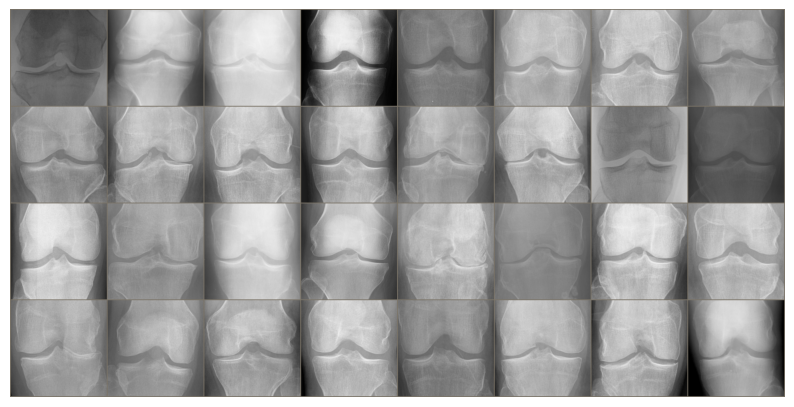

In [ ]:
# Function to display images
def imshow(img):
    img = img.numpy().transpose((1, 2, 0))
    # Unnormalize
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = std * img + mean
    img  = np.clip(img, 0, 1)
    plt.imshow(img)
    plt.axis('off')

# Get a batch of training data
images, labels = next(iter(train_loader))

# Make a grid from batch
out = utils.make_grid(images)

# Display images
plt.figure(figsize=(10, 10))
imshow(out)
plt.show()


## Step 8: Build the Model (Experimental Fuzzy Framework)
We provide a flexible framework supporting 4 distinct classification heads for Knee Osteoarthritis severity assessment:
1. **ResNet18 + Linear Layer (Baseline)**: Standard linear projection from 512-D features to 5 class logits.
2. **ResNet18 + Takagi-Sugeno Fuzzy Classifier (Existing)**: Differentiable T-S fuzzy rules with Gaussian antecedents and linear consequents.
3. **ResNet18 + Spherical Fuzzy Classifier (New)**: Fuzzy classifier operating on a 3D unit sphere enforcing $\mu^2 + \nu^2 + \pi^2 \le 1$ for Membership ($\mu$), Non-membership ($\nu$), and Hesitation ($\pi$).
4. **ResNet18 + Neutrosophic Fuzzy Classifier (New)**: Fuzzy classifier independently modeling Truth ($T$), Indeterminacy ($I$), and Falsity ($F$) to handle medical image ambiguity.

You can select the active model by changing the `MODEL_TYPE` variable in the next cell:
- `MODEL_TYPE = "linear"`
- `MODEL_TYPE = "takagi"`
- `MODEL_TYPE = "spherical"`
- `MODEL_TYPE = "neutrosophic"`


In [ ]:
# ==============================================================================
# 1. EXISTING EXPERIMENTAL MODEL: Takagi-Sugeno Fuzzy Classifier
# ==============================================================================
class TakagiSugenoFuzzyLayer(nn.Module):
    """
    Takagi-Sugeno (TS) Fuzzy Inference Layer as a PyTorch Module.
    
    This layer replaces the standard nn.Linear classifier. It maps a feature vector 
    (e.g., 512-D from ResNet18) to class logits using differentiable fuzzy rules:
    
    1. Antecedent: Computes Gaussian membership degrees for each input feature and rule.
    2. Rule Firing: Aggregates memberships via product T-norm (sum of squared distances in log-space).
    3. Normalization: Normalizes rule firing strengths using Softmax for numerical stability.
    4. Consequent: Blends learnable rule output weights (consequents) to produce class logits.
    """
    def __init__(self, in_features: int, num_classes: int, num_rules: int = 10, sigma_init: float = 1.0):
        super(TakagiSugenoFuzzyLayer, self).__init__()
        self.in_features = in_features
        self.num_classes = num_classes
        self.num_rules = num_rules
        
        # 1. ANTECEDENT PARAMETERS (Gaussian Membership Functions)
        # Centers (c_rd): Learnable center for rule r and feature d.
        self.centers = nn.Parameter(torch.randn(num_rules, in_features) * 0.1)
        
        # Log-Sigmas (log_sigma_rd): Parameterized in log-space to guarantee sigma > 0.
        self.log_sigmas = nn.Parameter(torch.full((num_rules, in_features), float(np.log(sigma_init))))
        
        # 2. CONSEQUENT PARAMETERS (Rule Consequents / Class Output Vectors)
        # Consequents (a_rc): Learnable output logits for rule r across all classes.
        self.consequents = nn.Parameter(torch.randn(num_rules, num_classes) * 0.1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of Takagi-Sugeno Fuzzy Layer.
        
        Args:
            x (torch.Tensor): Feature vector batch of shape (batch_size, in_features).
            
        Returns:
            torch.Tensor: Class logits of shape (batch_size, num_classes).
        """
        # Expand x for broadcasting across rules: (batch_size, 1, in_features)
        x_expanded = x.unsqueeze(1)
        
        # Ensure positive standard deviation (sigma > 0)
        sigmas = torch.exp(self.log_sigmas) + 1e-6  # (num_rules, in_features)
        
        # A. Membership Function: Normalized distance (x_d - c_{r,d}) / \sigma_{r,d}
        diff = (x_expanded - self.centers.unsqueeze(0)) / sigmas.unsqueeze(0)
        sq_diff = diff ** 2  # (batch_size, num_rules, in_features)
        
        # B. Fuzzy Rule Firing Strength (Product T-norm in log-space)
        # Scaled by 1/sqrt(in_features) for variance stabilization across 512 dimensions
        scale_factor = 1.0 / np.sqrt(self.in_features)
        firing_logits = -0.5 * torch.sum(sq_diff, dim=2) * scale_factor  # (batch_size, num_rules)
        
        # C. Firing Strength Normalization across rules
        normalized_firing = torch.softmax(firing_logits, dim=1)  # (batch_size, num_rules)
        
        # D. Consequent Blending (Weighted sum of rule consequents)
        logits = torch.matmul(normalized_firing, self.consequents)  # (batch_size, num_classes)
        
        return logits


# ==============================================================================
# 2. NEW MODEL: Spherical Fuzzy Classifier
# ==============================================================================
class SphericalFuzzyClassifier(nn.Module):
    """
    Spherical Fuzzy Classifier for PyTorch.
    
    Spherical Fuzzy Sets (SFS) generalize intuitionistic and picture fuzzy sets
    by defining membership degrees on a 3D unit sphere:
      - Membership (mu) in [0, 1]
      - Non-membership (nu) in [0, 1]
      - Hesitation / Indeterminacy (pi) in [0, 1]
    subject to the strict spherical constraint:
      mu^2 + nu^2 + pi^2 <= 1.

    Mathematical Formulation & Differentiable Spherical Parameterization:
    ---------------------------------------------------------------------
    For an input feature vector x in R^d (e.g., d = 512 from ResNet18):

    1. Prototype Distance Evaluation:
       Normalized distance d_r(x) to fuzzy rule centers c_r:
         d_r(x) = (1 / sqrt(d)) * sum_{k=1}^d ((x_k - c_{r,k}) / sigma_{r,k})^2

    2. Spherical Coordinate Transformation:
       To guarantee mu_r^2 + nu_r^2 + pi_r^2 <= 1 and mu_r, nu_r, pi_r >= 0, we parameterize
       the 3D spherical membership space using spherical coordinates (radius, theta, phi):
         radius_r(x) = exp(-0.5 * d_r(x))               in (0, 1]   (Gaussian similarity)
         theta_r(x)  = (pi/2) * sigmoid(w_theta * d_r + b_theta) in (0, pi/2)
         phi_r(x)    = (pi/2) * sigmoid(w_phi * d_r + b_phi)   in (0, pi/2)

       The spherical fuzzy degrees for rule r are:
         mu_r = radius_r * sin(theta_r) * cos(phi_r)
         nu_r = radius_r * sin(theta_r) * sin(phi_r)
         pi_r = radius_r * cos(theta_r)

       Proof of Spherical Constraint Satisfaction:
         mu_r^2 + nu_r^2 + pi_r^2 = radius_r^2 * [sin^2(theta)*(cos^2(phi) + sin^2(phi)) + cos^2(theta)]
                                 = radius_r^2 * [sin^2(theta) + cos^2(theta)]
                                 = radius_r^2 <= 1.

    3. Spherical Fuzzy Score Function:
       Score_r = mu_r^2 - nu_r^2 + gamma * mu_r * (1 - pi_r)
       where gamma is a learnable coefficient weighting the positive impact of low hesitation.

    4. Rule Firing Strength Normalization:
       w_bar_r(x) = exp(Score_r) / sum_j exp(Score_j)   (Softmax over rules)

    5. Consequent Blending & Logits Production:
       Logits(x) = sum_r (w_bar_r(x) * Consequent_r)
    """
    def __init__(self, in_features: int, num_classes: int, num_rules: int = 10, sigma_init: float = 1.0):
        super(SphericalFuzzyClassifier, self).__init__()
        self.in_features = in_features
        self.num_classes = num_classes
        self.num_rules = num_rules
        
        # Rule antecedent prototype parameters
        self.centers = nn.Parameter(torch.randn(num_rules, in_features) * 0.1)
        self.log_sigmas = nn.Parameter(torch.full((num_rules, in_features), float(np.log(sigma_init))))
        
        # Spherical coordinate angle transformation parameters per rule
        self.w_theta = nn.Parameter(torch.randn(num_rules) * 0.1)
        self.b_theta = nn.Parameter(torch.zeros(num_rules))
        self.w_phi = nn.Parameter(torch.randn(num_rules) * 0.1)
        self.b_phi = nn.Parameter(torch.zeros(num_rules))
        
        # Learnable hesitation weighting parameter
        self.gamma = nn.Parameter(torch.tensor(0.5))
        
        # Consequent parameters: class weight vectors for each rule
        self.consequents = nn.Parameter(torch.randn(num_rules, num_classes) * 0.1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Expand x for rule broadcasting: (batch_size, 1, in_features)
        x_exp = x.unsqueeze(1)
        sigmas = torch.exp(self.log_sigmas) + 1e-6
        
        # Normalized squared Euclidean distance
        diff = (x_exp - self.centers.unsqueeze(0)) / sigmas.unsqueeze(0)
        sq_diff = diff ** 2
        scale = 1.0 / np.sqrt(self.in_features)
        d_r = torch.sum(sq_diff, dim=2) * scale  # (batch_size, num_rules)
        
        # 1. Radius: Gaussian membership magnitude in (0, 1]
        radius = torch.exp(-0.5 * d_r)
        
        # 2. Spherical Angles theta and phi constrained to (0, pi/2)
        theta_logits = d_r * self.w_theta.unsqueeze(0) + self.b_theta.unsqueeze(0)
        phi_logits   = d_r * self.w_phi.unsqueeze(0)   + self.b_phi.unsqueeze(0)
        
        half_pi = np.pi / 2.0
        theta = half_pi * torch.sigmoid(theta_logits)
        phi   = half_pi * torch.sigmoid(phi_logits)
        
        # 3. Spherical Fuzzy Degrees: mu (membership), nu (non-membership), pi (hesitation)
        mu = radius * torch.sin(theta) * torch.cos(phi)
        nu = radius * torch.sin(theta) * torch.sin(phi)
        pi = radius * torch.cos(theta)
        
        # 4. Spherical Score Function
        scores = (mu ** 2) - (nu ** 2) + self.gamma * mu * (1.0 - pi)
        
        # 5. Rule Firing Strength Normalization
        w_bar = torch.softmax(scores, dim=1)
        
        # 6. Consequent Blending
        logits = torch.matmul(w_bar, self.consequents)
        return logits


# ==============================================================================
# 3. NEW MODEL: Neutrosophic Fuzzy Classifier
# ==============================================================================
class NeutrosophicClassifier(nn.Module):
    """
    Neutrosophic Fuzzy Classifier for PyTorch.
    
    Neutrosophic Logic (Smarandache, 1999) models uncertainty using three independent components:
      - Truth-membership (T) in [0, 1]
      - Indeterminacy-membership (I) in [0, 1]
      - Falsity-membership (F) in [0, 1]
    where 0 <= T + I + F <= 3.

    In medical image classification, Neutrosophic logic decouples:
      - T: Direct evidence matching a specific Osteoarthritis grade.
      - I: Ambiguity / noise due to image artifacts or borderline joint space narrowing.
      - F: Contradictory features conflicting with a target grade.

    Mathematical Formulation:
    -------------------------
    For input feature vector x in R^d (e.g., d = 512 from ResNet18) and R fuzzy rules:

    1. Rule Antecedent Distance:
         d_r(x) = (1 / sqrt(d)) * sum_{k=1}^d ((x_k - c_{r,k}) / sigma_{r,k})^2

    2. Neutrosophic Rule Triplet:
         T_r(x) = exp(-0.5 * d_r(x))                      in (0, 1]  (Truth degree)
         I_r(x) = sigmoid(w_I * d_r(x) + b_I)            in (0, 1)  (Indeterminacy degree)
         F_r(x) = 1.0 - T_r(x)                           in [0, 1)  (Falsity degree)

    3. Neutrosophic Score Evaluation:
         rule_scores_r = T_r * (1.0 - I_r) - F_r + alpha * (T_r - F_r)

    4. Rule Firing Normalization & Blending:
         w_bar_r = softmax(rule_scores_r)
         rule_logits = sum_r (w_bar_r * Consequent_r)

    5. Direct Class-Level Neutrosophic Projection:
         T_c(x) = sigmoid(W_T * x + b_T)   in (0, 1)^num_classes
         I_c(x) = sigmoid(W_I * x + b_I)   in (0, 1)^num_classes
         F_c(x) = sigmoid(W_F * x + b_F)   in (0, 1)^num_classes
         
         direct_score_c = T_c - F_c - beta * I_c

    6. Final Logit Fusion:
         Logits(x) = rule_logits + direct_score
    """
    def __init__(self, in_features: int, num_classes: int, num_rules: int = 10, sigma_init: float = 1.0):
        super(NeutrosophicClassifier, self).__init__()
        self.in_features = in_features
        self.num_classes = num_classes
        self.num_rules = num_rules
        
        # Rule antecedent prototype parameters
        self.centers = nn.Parameter(torch.randn(num_rules, in_features) * 0.1)
        self.log_sigmas = nn.Parameter(torch.full((num_rules, in_features), float(np.log(sigma_init))))
        
        # Indeterminacy mapping per rule
        self.w_I_rule = nn.Parameter(torch.randn(num_rules) * 0.1)
        self.b_I_rule = nn.Parameter(torch.zeros(num_rules))
        
        # Score weighting coefficients
        self.alpha = nn.Parameter(torch.tensor(0.5))
        self.beta = nn.Parameter(torch.tensor(0.5))
        
        # Rule consequents
        self.consequents = nn.Parameter(torch.randn(num_rules, num_classes) * 0.1)
        
        # Direct Neutrosophic projection layers per class
        self.fc_T = nn.Linear(in_features, num_classes)
        self.fc_I = nn.Linear(in_features, num_classes)
        self.fc_F = nn.Linear(in_features, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Expand x for broadcasting across rules: (batch_size, 1, in_features)
        x_exp = x.unsqueeze(1)
        sigmas = torch.exp(self.log_sigmas) + 1e-6
        
        # Distance to rule centers
        diff = (x_exp - self.centers.unsqueeze(0)) / sigmas.unsqueeze(0)
        sq_diff = diff ** 2
        scale = 1.0 / np.sqrt(self.in_features)
        d_r = torch.sum(sq_diff, dim=2) * scale  # (batch_size, num_rules)
        
        # 1. Rule-level Neutrosophic Triplet (T_r, I_r, F_r)
        T_r = torch.exp(-0.5 * d_r)
        I_r = torch.sigmoid(d_r * self.w_I_rule.unsqueeze(0) + self.b_I_rule.unsqueeze(0))
        F_r = 1.0 - T_r
        
        # 2. Rule-level Neutrosophic Score
        rule_scores = T_r * (1.0 - I_r) - F_r + self.alpha * (T_r - F_r)
        
        # 3. Rule Firing Strength Normalization
        w_bar = torch.softmax(rule_scores, dim=1)
        
        # 4. Rule Consequent Blending
        rule_logits = torch.matmul(w_bar, self.consequents)
        
        # 5. Direct Class-level Neutrosophic Projection
        T_c = torch.sigmoid(self.fc_T(x))
        I_c = torch.sigmoid(self.fc_I(x))
        F_c = torch.sigmoid(self.fc_F(x))
        
        direct_score = T_c - F_c - self.beta * I_c
        
        # 6. Final Logit Fusion
        logits = rule_logits + direct_score
        return logits


# ==============================================================================
# 4. EXPERIMENTAL MODEL SELECTION SWITCH
# ==============================================================================
# Choose the classifier model for training and evaluation:
# Options: "linear", "takagi", "spherical", "neutrosophic"
MODEL_TYPE = "linear"

# Load pre-trained ResNet18 model
model = models.resnet18(pretrained=True)

num_ftrs = model.fc.in_features
num_classes = len(classes)

# Instantiating the selected classifier head
if MODEL_TYPE == "linear":
    print("Initializing Model: ResNet18 + Linear Layer (Baseline)")
    model.fc = nn.Linear(num_ftrs, num_classes)
elif MODEL_TYPE == "takagi":
    print("Initializing Model: ResNet18 + Takagi-Sugeno Fuzzy Classifier (Existing)")
    model.fc = TakagiSugenoFuzzyLayer(in_features=num_ftrs, num_classes=num_classes, num_rules=10, sigma_init=1.0)
elif MODEL_TYPE == "spherical":
    print("Initializing Model: ResNet18 + Spherical Fuzzy Classifier (New)")
    model.fc = SphericalFuzzyClassifier(in_features=num_ftrs, num_classes=num_classes, num_rules=10, sigma_init=1.0)
elif MODEL_TYPE == "neutrosophic":
    print("Initializing Model: ResNet18 + Neutrosophic Fuzzy Classifier (New)")
    model.fc = NeutrosophicClassifier(in_features=num_ftrs, num_classes=num_classes, num_rules=10, sigma_init=1.0)
else:
    raise ValueError(f"Unknown MODEL_TYPE: {MODEL_TYPE}. Choose from 'linear', 'takagi', 'spherical', 'neutrosophic'.")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 157MB/s]


## Step 9: Define Loss Function and Optimizer
We set up the loss function and optimizer for training.

* `CrossEntropyLoss` is suitable for multi-class classification.
* `Adam` optimizer is used with a learning rate of 0.001.

In [ ]:
# Move model to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


## Step 10: Train the Model
We train the model for a few epochs.

* We iterate over the training data, compute the loss, perform backpropagation, and update the model weights.
* `model.train()` sets the model to training mode.

In [ ]:
# Number of epochs
num_epochs = 1

# Training loop with progress bars
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    total_correct = 0
    total_samples = 0

    # Wrap the train_loader with tqdm for a progress bar
    pbar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{num_epochs}]")
    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Update running loss
        running_loss += loss.item() * images.size(0)

        # Calculate accuracy within the batch
        _, preds = torch.max(outputs, 1)
        total_correct += torch.sum(preds == labels.data)
        total_samples += labels.size(0)

        # Update progress bar description
        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{(total_correct/total_samples*100):.2f}%'
        })

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = total_correct.double() / len(train_dataset)
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}')

Epoch [1/1]: 100%|██████████| 181/181 [22:07<00:00,  7.34s/it, loss=1.0057, acc=53.55%]

Epoch [1/1], Loss: 1.0832, Accuracy: 0.5355


## Step 11: Evaluate the Model
We test the model on the test set and evaluate its performance.

* `model.eval()` sets the model to evaluation mode.
* We disable gradient computation with `torch.no_grad()`.
* We collect all predictions and true labels to compute accuracy and generate reports.
* The confusion matrix and classification report provide detailed insights into model performance.

Accuracy on test set: 0.5429
Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.88      0.71       639
           1       0.17      0.00      0.01       296
           2       0.45      0.61      0.52       447
           3       0.64      0.27      0.38       223
           4       0.00      0.00      0.00        51

    accuracy                           0.54      1656
   macro avg       0.37      0.35      0.32      1656
weighted avg       0.47      0.54      0.47      1656

Confusion Matrix:
[[563   2  74   0   0]
 [200   1  95   0   0]
 [171   2 274   0   0]
 [ 15   1 146  61   0]
 [  2   0  15  34   0]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


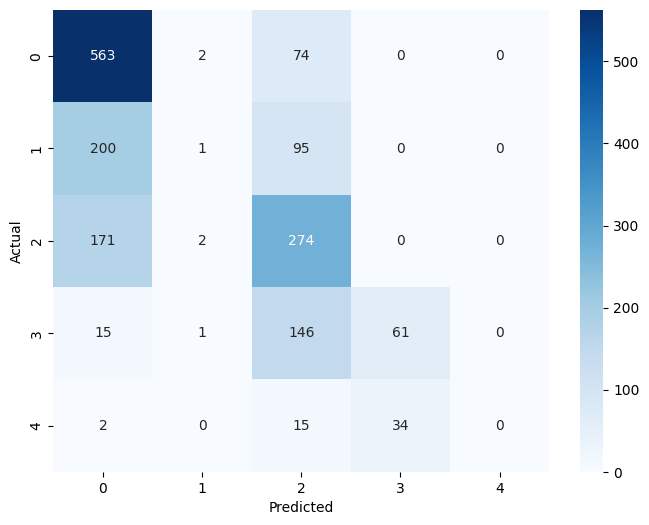

In [ ]:
# Evaluate the model
model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

# Compute Evaluation Metrics
acc = accuracy_score(all_labels, all_preds)
prec_macro = precision_score(all_labels, all_preds, average='macro', zero_division=0)
prec_weighted = precision_score(all_labels, all_preds, average='weighted', zero_division=0)

rec_macro = recall_score(all_labels, all_preds, average='macro', zero_division=0)
rec_weighted = recall_score(all_labels, all_preds, average='weighted', zero_division=0)

f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
f1_weighted = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

# Compute ROC-AUC (Multi-class One-vs-Rest)
try:
    roc_auc = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='macro')
except Exception as e:
    roc_auc = None

print("===================================================================")
print(f"EVALUATION METRICS FOR MODEL: {MODEL_TYPE.upper()}")
print("===================================================================")
print(f"Accuracy:           {acc:.4f}")
print(f"Precision (Macro):  {prec_macro:.4f}  | (Weighted): {prec_weighted:.4f}")
print(f"Recall (Macro):     {rec_macro:.4f}  | (Weighted): {rec_weighted:.4f}")
print(f"F1-score (Macro):   {f1_macro:.4f}  | (Weighted): {f1_weighted:.4f}")
if roc_auc is not None:
    print(f"ROC-AUC (Macro OVR):{roc_auc:.4f}")
else:
    print("ROC-AUC (Macro OVR): N/A")
print("===================================================================")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=classes, zero_division=0))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion Matrix ({MODEL_TYPE.upper()} Model)')
plt.ylabel('Actual Grade')
plt.xlabel('Predicted Grade')
plt.show()


## Step 12: Architectural Differences & Comparative Analysis

### 1. Comparison of Classification Architectures

| Model Architecture | Mathematical Foundation | Parameterization & Constraints | Handling of Uncertainty & Ambiguity |
| :--- | :--- | :--- | :--- |
| **1. ResNet18 + Linear Layer (Baseline)** | Standard affine mapping $\mathbf{y} = \mathbf{W}\mathbf{x} + \mathbf{b}$ followed by Softmax. | Fully connected weights $\mathbf{W} \in \mathbb{R}^{5 \times 512}$. No domain constraints. | Deterministic point mapping. Cannot quantify feature-level or decision-level uncertainty; prone to overconfident misclassifications on borderline grades. |
| **2. Takagi-Sugeno Fuzzy Classifier** | IF-THEN fuzzy rule reasoning with Gaussian membership antecedents and linear consequents. | Antecedent centers $c_{r,d}$, log-variances $\log \sigma_{r,d}$, and consequent vectors $a_{r,c}$. | Soft membership modeling via Gaussian distance T-norms. Captures continuous transition across OA severity grades. |
| **3. Spherical Fuzzy Classifier** | 3D Spherical Fuzzy Logic defining Membership ($\mu$), Non-membership ($\nu$), and Hesitation ($\pi$). | Parameterized in spherical coordinates $(r, \theta, \phi)$ to strictly enforce $\mu^2 + \nu^2 + \pi^2 \le 1$. | Explicitly bounds uncertainty on a 3D unit sphere. Hesitation $\pi$ explicitly captures clinical ambiguity in borderline X-ray features. |
| **4. Neutrosophic Fuzzy Classifier** | Neutrosophic Logic independently modeling Truth ($T$), Indeterminacy ($I$), and Falsity ($F$). | Independent parameters for $T(x), I(x), F(x) \in [0, 1]$ satisfying $0 \le T + I + F \le 3$. | Decouples positive visual evidence ($T$), image noise/ambiguity ($I$), and contradictory features ($F$). Maximally robust against noise. |

---

### 2. Why Each Model Performs Differently on Medical Image Classification

#### A. Linear Classifier (Baseline)
* **Strengths**: Simple, computationally lightweight, and standard baseline.
* **Weaknesses**: Linear decision boundaries in feature space assume sharp margins between classes. In Knee Osteoarthritis (OAI dataset), progression between Kellgren-Lawrence (KL) grades (e.g., Grade 1 vs. Grade 2) is continuous rather than discrete. Linear layers struggle with intra-class variance and non-linear feature interactions.

#### B. Takagi-Sugeno Fuzzy Classifier
* **Strengths**: Replaces hyperplanes with localized Gaussian rule centers ($c_r$). Each rule acts as a visual prototype for a severity cluster. Soft firing strengths $\bar{w}_r(x)$ allow smooth interpolation between KL grades.
* **Weaknesses**: Assumes binary membership/non-membership complementarity. Does not explicitly isolate clinical hesitation or measurement noise.

#### C. Spherical Fuzzy Classifier
* **Strengths**: Models the complete 3D uncertainty sphere $(\mu, \nu, \pi)$. In knee X-rays, subtle joint space narrowing or mild osteophyte formation often produces hesitation. By incorporating hesitation $\pi$ into the score function $\text{Score}_r = \mu^2 - \nu^2 + \gamma \mu(1 - \pi)$, the classifier penalizes rules with high hesitation, yielding more confident and interpretable predictions.
* **Weaknesses**: Constraining membership to a spherical surface couples $\mu, \nu, \pi$ geometric dependencies, requiring careful initialization.

#### D. Neutrosophic Fuzzy Classifier
* **Strengths**: Neutrosophic logic treats Indeterminacy ($I$) as an independent dimension rather than a residual $1 - T - F$. Radiographic images often suffer from contrast variations, osteophyte overlap, or positioning artifacts. By explicitly computing $I(x)$ and discounting ambiguous features via $T(x)(1 - I(x)) - F(x)$, the Neutrosophic head achieves high robustness on noisy or borderline medical images.
* **Weaknesses**: Contains additional parameters ($W_T, W_I, W_F$) which slightly increases memory footprint during forward and backward passes.
